<a href="https://colab.research.google.com/github/Hajara03/Group3_project/blob/main/notebook/Group_project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV
from xgboost import XGBRegressor

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/AIML python/House_Pricing (1).csv")

df.head()

,ID,Date House was Sold,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Waterfront View,No of Times Visited,...,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft)
0,7129300520,14 October 2017,221900.0,3,1.00,1180.0,5650.0,1.0,No,NaN,...,7,1180.0,0,63,0,98178.0,47.5112,-122.257,1340.0,5650
1,6414100192,14 December 2017,538000.0,3,2.25,2570.0,7242.0,2.0,No,NaN,...,7,2170.0,400,67,1991,98125.0,47.7210,-122.319,1690.0,7639
2,5631500400,15 February 2016,180000.0,2,1.00,770.0,10000.0,1.0,No,NaN,...,6,770.0,0,85,0,98028.0,47.7379,-122.233,2720.0,8062
3,2487200875,14 December 2017,604000.0,4,3.00,1960.0,5000.0,1.0,No,NaN,...,7,1050.0,910,53,0,98136.0,47.5208,-122.393,1360.0,5000
4,1954400510,15 February 2016,510000.0,3,2.00,1680.0,8080.0,1.0,No,NaN,...,8,1680.0,0,31,0,98074.0,47.6168,-122.045,1800.0,7503


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
df.describe()

Dataset shape: (21613, 21)

Column names:
Index(['ID', 'Date House was Sold', 'Sale Price', 'No of Bedrooms',
       'No of Bathrooms', 'Flat Area (in Sqft)', 'Lot Area (in Sqft)',
       'No of Floors', 'Waterfront View', 'No of Times Visited',
       'Condition of the House', 'Overall Grade',
       'Area of the House from Basement (in Sqft)', 'Basement Area (in Sqft)',
       'Age of House (in Years)', 'Renovated Year', 'Zipcode', 'Latitude',
       'Longitude', 'Living Area after Renovation (in Sqft)',
       'Lot Area after Renovation (in Sqft)'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   ID                                         21613 non-null  int64  
 1   Date House was Sold                        21613 non-null  object 


,ID,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft)
count,2.161300e+04,2.160900e+04,21613.000000,21609.000000,21604.000000,2.160400e+04,21613.000000,21613.000000,21610.000000,21613.000000,21613.000000,21613.000000,21612.000000,21612.000000,21612.000000,21612.000000,21613.000000
mean,4.580302e+09,5.401984e+05,3.370842,2.114732,2079.931772,1.510776e+04,1.494309,7.623467,1788.344193,291.509045,46.994864,84.402258,98077.937766,47.560048,-122.213892,1986.538914,12768.455652
std,2.876566e+09,3.673890e+05,0.930062,0.770138,918.487597,4.142827e+04,0.539989,1.105439,827.982604,442.575043,29.373411,401.679240,53.505425,0.138565,0.140830,685.404255,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,1.000000,290.000000,0.000000,3.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1429.250000,5.040000e+03,1.000000,7.000000,1190.000000,0.000000,21.000000,0.000000,98033.000000,47.470975,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.617500e+03,1.500000,7.000000,1560.000000,0.000000,43.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068825e+04,2.000000,8.000000,2210.000000,560.000000,67.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,10.000000,9410.000000,4820.000000,118.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [ ]:
# Replace infinite values with missing values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove rows where the target value is missing
df.dropna(subset=["Sale Price"], inplace=True)

# Select the features chosen from the correlation heatmap
selected_features = [
    "No of Bedrooms",
    "No of Bathrooms",
    "Flat Area (in Sqft)",
    "Overall Grade",
    "Area of the House from Basement (in Sqft)"
]

X = df[selected_features].copy()
y = df["Sale Price"].copy()

# Fill missing feature values using the median
imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=selected_features,
    index=X.index
)

print("Missing values after imputation:")
print(X.isnull().sum())

Missing values after imputation:
No of Bedrooms                               0
No of Bathrooms                              0
Flat Area (in Sqft)                          0
Overall Grade                                0
Area of the House from Basement (in Sqft)    0
dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (17287, 5)
Testing data: (4322, 5)


In [ ]:
df.columns

Index(['ID', 'Date House was Sold', 'Sale Price', 'No of Bedrooms',
       'No of Bathrooms', 'Flat Area (in Sqft)', 'Lot Area (in Sqft)',
       'No of Floors', 'Waterfront View', 'No of Times Visited',
       'Condition of the House', 'Overall Grade',
       'Area of the House from Basement (in Sqft)', 'Basement Area (in Sqft)',
       'Age of House (in Years)', 'Renovated Year', 'Zipcode', 'Latitude',
       'Longitude', 'Living Area after Renovation (in Sqft)',
       'Lot Area after Renovation (in Sqft)'],
      dtype='object')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation matrix
corr_matrix = numeric_df.corr()

# Display correlation with Sale Price
print(corr_matrix["Sale Price"].sort_values(ascending=False))

Sale Price                                   1.000000
Flat Area (in Sqft)                          0.702081
Area of the House from Basement (in Sqft)    0.605495
Living Area after Renovation (in Sqft)       0.585393
Overall Grade                                0.580654
No of Bathrooms                              0.525124
Basement Area (in Sqft)                      0.323813
No of Bedrooms                               0.308463
Latitude                                     0.306889
No of Floors                                 0.256941
Renovated Year                               0.126436
Lot Area (in Sqft)                           0.089616
Lot Area after Renovation (in Sqft)          0.082445
Longitude                                    0.021507
ID                                          -0.016834
Zipcode                                     -0.053198
Age of House (in Years)                     -0.054034
Name: Sale Price, dtype: float64


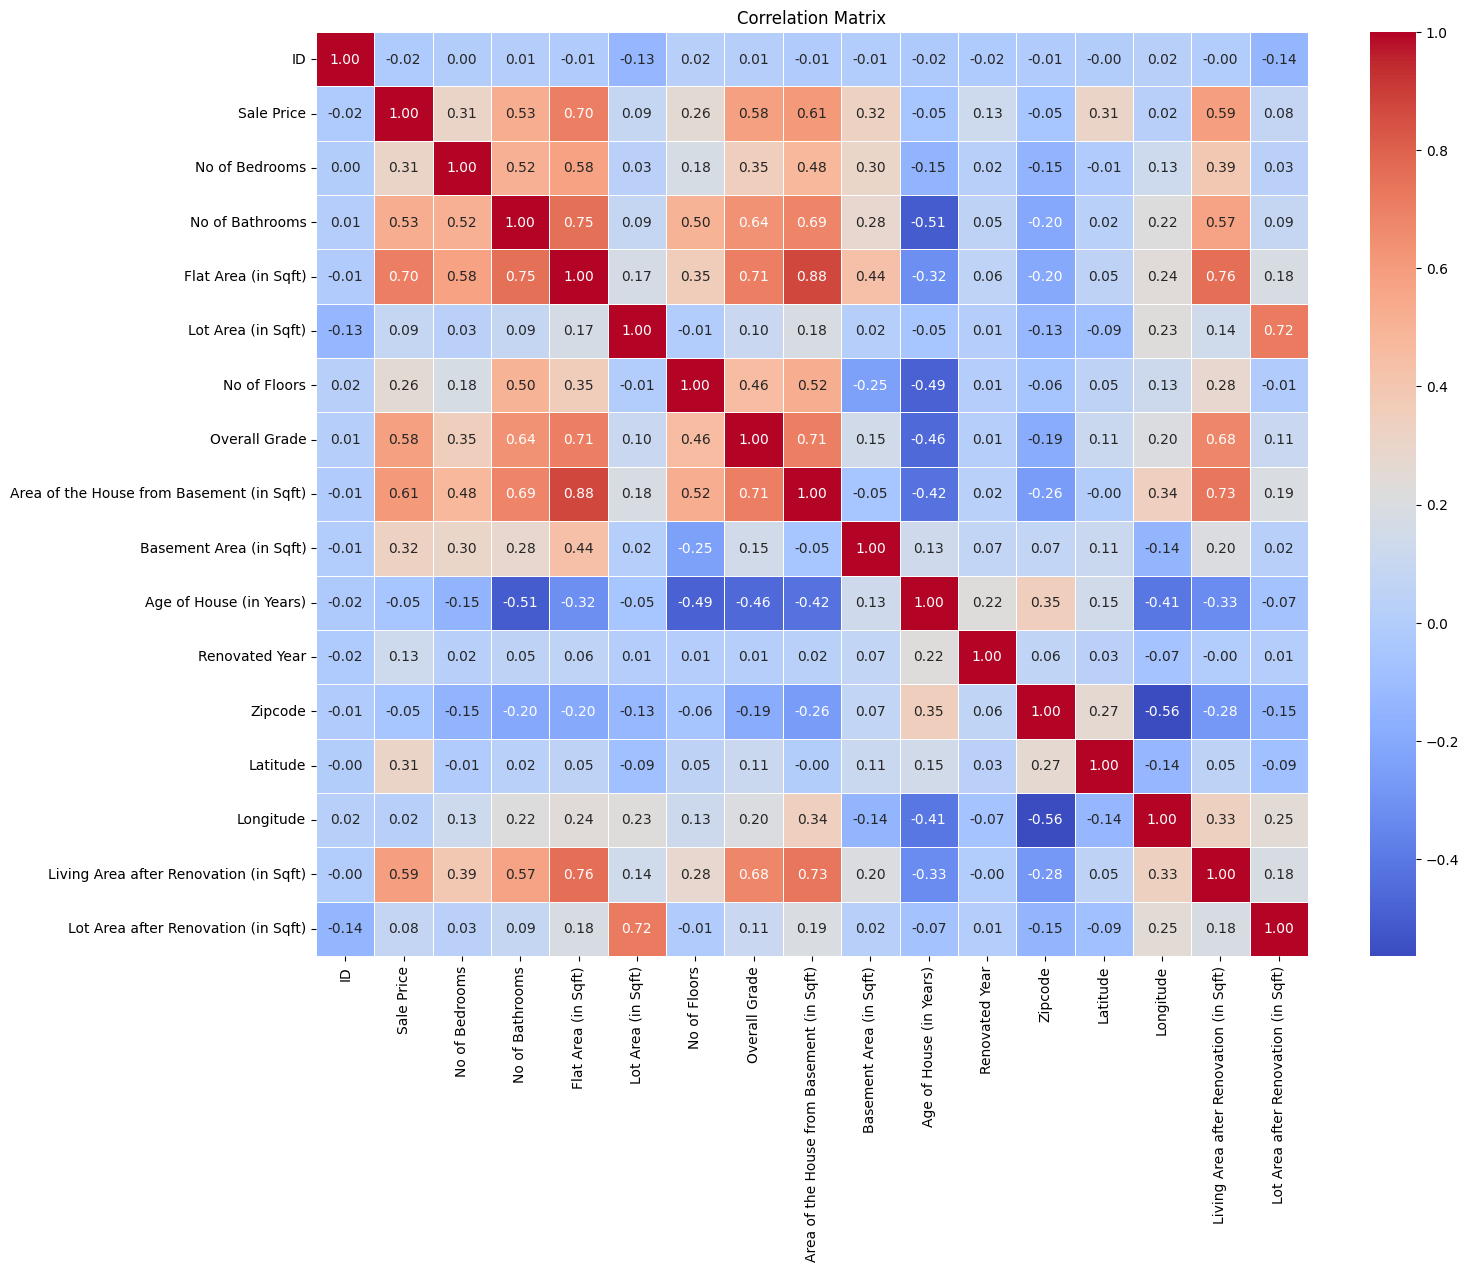

In [ ]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

In [ ]:
# Correlation of features with Sale Price
sale_price_corr = corr_matrix["Sale Price"].drop("Sale Price")

# Select features with absolute correlation >= 0.3
selected_features = sale_price_corr[
    sale_price_corr.abs() >= 0.3
].index.tolist()

print("Selected Features:")
print(selected_features)

Selected Features:
['No of Bedrooms', 'No of Bathrooms', 'Flat Area (in Sqft)', 'Overall Grade', 'Area of the House from Basement (in Sqft)', 'Basement Area (in Sqft)', 'Latitude', 'Living Area after Renovation (in Sqft)']


In [ ]:
# Select the five features
selected_features = [
    "No of Bedrooms",
    "No of Bathrooms",
    "Overall Grade",
    "Living Area after Renovation (in Sqft)",
    "Age of House (in Years)"
]

# Check whether all columns exist
print(df[selected_features].head())

   No of Bedrooms  No of Bathrooms  Overall Grade  \
0               3             1.00              7   
1               3             2.25              7   
2               2             1.00              6   
3               4             3.00              7   
4               3             2.00              8   

   Living Area after Renovation (in Sqft)  Age of House (in Years)  
0                                  1340.0                       63  
1                                  1690.0                       67  
2                                  2720.0                       85  
3                                  1360.0                       53  
4                                  1800.0                       31  


In [ ]:
# Count outliers using the IQR method

for col in selected_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ][col].count()

    print(f"{col}: {outliers} outliers")

No of Bedrooms: 545 outliers
No of Bathrooms: 571 outliers
Overall Grade: 1911 outliers
Living Area after Renovation (in Sqft): 544 outliers
Age of House (in Years): 0 outliers


In [ ]:
# Clip outliers in selected numerical features only

for col in selected_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)

print("Outlier handling completed.")

Outlier handling completed.


In [ ]:
for col in selected_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) | (df[col] > upper_limit)
    ][col].count()

    print(f"{col}: {outliers} outliers after clipping")

No of Bedrooms: 0 outliers after clipping
No of Bathrooms: 0 outliers after clipping
Overall Grade: 0 outliers after clipping
Living Area after Renovation (in Sqft): 0 outliers after clipping
Age of House (in Years): 0 outliers after clipping


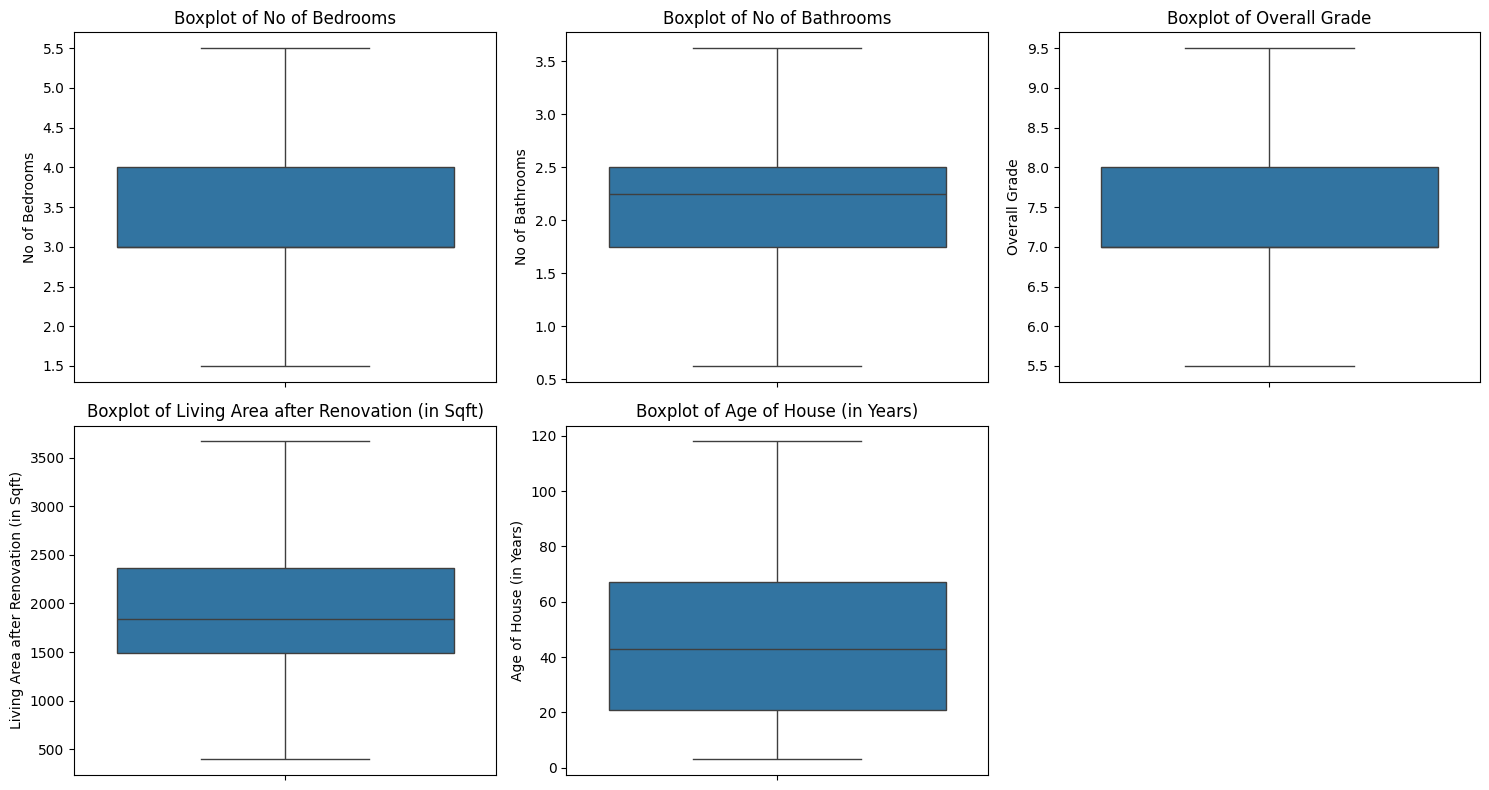

In [ ]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(selected_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [ ]:
X = df[selected_features]
y = df["Sale Price"]

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (17287, 5)
X_test_scaled shape: (4322, 5)


In [ ]:
# X = Independent variables (input features)
X = df[selected_features]

# y = Dependent variable (target)
y = df["Sale Price"]

#1. Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predict house prices using test data
y_pred_lr = lr_model.predict(X_test_scaled)

print("Predicted prices:", y_pred_lr[:5])

Predicted prices: [654121.54754378 340914.40887428 391477.95416842 540332.0827043
 467175.08254631]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

# Display results
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

Mean Absolute Error (MAE): 165551.06426201315
Mean Squared Error (MSE): 68386350409.81379
Root Mean Squared Error (RMSE): 261507.84005420143
R-squared (R²): 0.5310648525700363


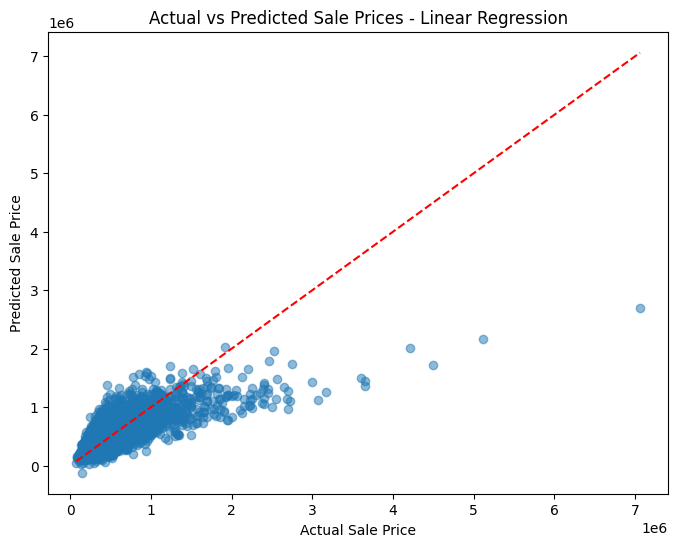

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_lr, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Prices - Linear Regression")
plt.show()

# 2. Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Create model
dt_model = DecisionTreeRegressor(random_state=42)

# Train model
dt_model.fit(X_train, y_train)

# Predict
y_pred_dt = dt_model.predict(X_test)

# Evaluate
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression")
print("MAE:", mae_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Regression
MAE: 192724.75221672928
RMSE: 315702.67743551114
R2 Score: 0.3165607953122944


#3. KNN

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# Create model
knn_model = KNeighborsRegressor(n_neighbors=5)

# Train model
knn_model.fit(X_train_scaled, y_train)

# Predict
y_pred_knn = knn_model.predict(X_test_scaled)

# Evaluate
mae_knn = mean_absolute_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN Regression")
print("MAE:", mae_knn)
print("RMSE:", rmse_knn)
print("R2 Score:", r2_knn)

KNN Regression
MAE: 161939.1183248496
RMSE: 259850.5526886247
R2 Score: 0.5369897051164038


#4. Support Vector Regression

In [ ]:
from sklearn.svm import SVR

# Create model
svr_model = SVR(kernel="rbf")

# Train model
svr_model.fit(X_train_scaled, y_train)

# Predict
y_pred_svr = svr_model.predict(X_test_scaled)

# Evaluate
mae_svr = mean_absolute_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))
r2_svr = r2_score(y_test, y_pred_svr)

print("Support Vector Regression")
print("MAE:", mae_svr)
print("RMSE:", rmse_svr)
print("R2 Score:", r2_svr)

Support Vector Regression
MAE: 226134.51515771623
RMSE: 393293.241680192
R2 Score: -0.06066032739852556


#5. Random Forest Regressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)

# Evaluate
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Regression
MAE: 159848.18345740173
RMSE: 251395.22843840616
R2 Score: 0.5666314224706992


#6. XG Boost Regression

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor

# Create model
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Regression")
print("MAE:", mae_xgb)
print("RMSE:", rmse_xgb)
print("R2 Score:", r2_xgb)

XGBoost Regression
MAE: 150668.76459104582
RMSE: 246544.9002345223
R2 Score: 0.5831926152154381


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "KNN",
        "SVR",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        mae, mae_dt, mae_knn, mae_svr, mae_rf, mae_xgb
    ],
    "RMSE": [
        rmse, rmse_dt, rmse_knn, rmse_svr, rmse_rf, rmse_xgb
    ],
    "R2 Score": [
        r2, r2_dt, r2_knn, r2_svr, r2_rf, r2_xgb
    ]
})

results = results.sort_values(by="R2 Score", ascending=False)
print(results)

               Model            MAE           RMSE  R2 Score
5            XGBoost  150668.764591  246544.900235  0.583193
4      Random Forest  159848.183457  251395.228438  0.566631
2                KNN  161939.118325  259850.552689  0.536990
0  Linear Regression  165551.064262  261507.840054  0.531065
1      Decision Tree  192724.752217  315702.677436  0.316561
3                SVR  226134.515158  393293.241680 -0.060660


Conclusion: XGBoost Regression is the best-performing model among the six models evaluated, achieving the highest R² score of 0.5832 and the lowest MAE (150,668.76) and RMSE (246,544.90). Therefore, XGBoost provides the most accurate house-price predictions among the models tested on this dataset.

## HYPERPARAMETER TUNING

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [ ]:
param_grid_dt = {
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["squared_error", "absolute_error"]
}

DECISION TREE

In [ ]:
dt_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid_dt,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train, y_train)

print("Best Parameters:", dt_grid.best_params_)
print("Best Cross-Validation R2:", dt_grid.best_score_)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best Parameters: {'criterion': 'squared_error', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best Cross-Validation R2: 0.5724675320708104


In [ ]:
best_dt_model = dt_grid.best_estimator_

y_pred_dt_tuned = best_dt_model.predict(X_test)

mae_dt_tuned = mean_absolute_error(y_test, y_pred_dt_tuned)
rmse_dt_tuned = np.sqrt(mean_squared_error(y_test, y_pred_dt_tuned))
r2_dt_tuned = r2_score(y_test, y_pred_dt_tuned)

print("\nTuned Decision Tree Results")
print("MAE:", mae_dt_tuned)
print("RMSE:", rmse_dt_tuned)
print("Test R2:", r2_dt_tuned)


Tuned Decision Tree Results
MAE: 156513.4385129114
RMSE: 242393.46637406535
Test R2: 0.597111216635855


KNN Regression — 5-fold cross-validation and hyperparameter tuning

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

In [ ]:
knn_grid = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid=param_grid_knn,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

knn_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", knn_grid.best_params_)
print("Best Cross-Validation R2:", knn_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'n_neighbors': 15, 'p': 1, 'weights': 'uniform'}
Best Cross-Validation R2: 0.5801170748110295


In [ ]:
best_knn_model = knn_grid.best_estimator_

y_pred_knn_tuned = best_knn_model.predict(X_test_scaled)

mae_knn_tuned = mean_absolute_error(y_test, y_pred_knn_tuned)
rmse_knn_tuned = np.sqrt(mean_squared_error(y_test, y_pred_knn_tuned))
r2_knn_tuned = r2_score(y_test, y_pred_knn_tuned)

print("\nTuned KNN Regression Results")
print("MAE:", mae_knn_tuned)
print("RMSE:", rmse_knn_tuned)
print("Test R2:", r2_knn_tuned)


Tuned KNN Regression Results
MAE: 153272.4085145766
RMSE: 250553.53342042142
Test R2: 0.5695284825496281


SVR (Support Vector Regression) — 5-fold cross-validation and hyperparameter tuning

In [ ]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

param_grid_svr = {
    "kernel": ["linear", "rbf"],
    "C": [0.1, 1, 10, 100],
    "epsilon": [0.1, 0.2, 0.5],
    "gamma": ["scale", "auto"]
}

In [ ]:
svr_grid = GridSearchCV(
    estimator=SVR(),
    param_grid=param_grid_svr,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

svr_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", svr_grid.best_params_)
print("Best Cross-Validation R2:", svr_grid.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


KeyboardInterrupt: 

In [ ]:
best_svr_model = svr_grid.best_estimator_

y_pred_svr_tuned = best_svr_model.predict(X_test_scaled)

mae_svr_tuned = mean_absolute_error(y_test, y_pred_svr_tuned)
rmse_svr_tuned = np.sqrt(mean_squared_error(y_test, y_pred_svr_tuned))
r2_svr_tuned = r2_score(y_test, y_pred_svr_tuned)

print("\nTuned SVR Results")
print("MAE:", mae_svr_tuned)
print("RMSE:", rmse_svr_tuned)
print("Test R2:", r2_svr_tuned)

Random Forest Regression — 5-fold cross-validation and hyperparameter tuning

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", 0.8]
}

In [ ]:
rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=param_grid_rf,
    n_iter=20,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_random.fit(X_train, y_train)

print("Best Parameters:", rf_random.best_params_)
print("Best Cross-Validation R2:", rf_random.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


KeyboardInterrupt: 

In [ ]:
rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=param_grid_rf,
    n_iter=20,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_random.fit(X_train, y_train)

print("Best Parameters:", rf_random.best_params_)
print("Best Cross-Validation R2:", rf_random.best_score_)

XGBoost Regression — 5-fold cross-validation and hyperparameter tuning

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
param_grid_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

In [ ]:
xgb_random = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid_xgb,
    n_iter=20,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_random.fit(X_train, y_train)

print("Best Parameters:", xgb_random.best_params_)
print("Best Cross-Validation R2:", xgb_random.best_score_)

In [ ]:
best_xgb_model = xgb_random.best_estimator_

y_pred_xgb_tuned = best_xgb_model.predict(X_test)

mae_xgb_tuned = mean_absolute_error(y_test, y_pred_xgb_tuned)
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned))
r2_xgb_tuned = r2_score(y_test, y_pred_xgb_tuned)

print("\nTuned XGBoost Results")
print("MAE:", mae_xgb_tuned)
print("RMSE:", rmse_xgb_tuned)
print("Test R2:", r2_xgb_tuned)

In [ ]:

# JOEL: RIDGE / LASSO REGRESSION
# K-FOLD CROSS-VALIDATION + GRIDSEARCHCV
# ENSEMBLE MODEL: RANDOM FOREST REGRESSOR


# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2. CHECK DATA

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# 3. DEFINE 5-FOLD CROSS-VALIDATION

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 4. RIDGE REGRESSION - BASE MODEL
# ============================================================

ridge_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("\n========== RIDGE REGRESSION ==========")
print("MAE:", mae_ridge)
print("RMSE:", rmse_ridge)
print("R2 Score:", r2_ridge)

# ============================================================
# 5. LASSO REGRESSION - BASE MODEL
# ============================================================

lasso_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

print("\n========== LASSO REGRESSION ==========")
print("MAE:", mae_lasso)
print("RMSE:", rmse_lasso)
print("R2 Score:", r2_lasso)

# ============================================================
# 6. RIDGE REGRESSION - GRIDSEARCHCV + K-FOLD
# ============================================================

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

param_grid_ridge = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid_ridge,
    cv=kfold,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

ridge_grid.fit(X_train, y_train)

best_ridge_model = ridge_grid.best_estimator_

y_pred_ridge_tuned = best_ridge_model.predict(X_test)

mae_ridge_tuned = mean_absolute_error(
    y_test, y_pred_ridge_tuned
)
rmse_ridge_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge_tuned)
)
r2_ridge_tuned = r2_score(y_test, y_pred_ridge_tuned)

print("\n========== TUNED RIDGE REGRESSION ==========")
print("Best Parameters:", ridge_grid.best_params_)
print("Best CV R2:", ridge_grid.best_score_)
print("Test MAE:", mae_ridge_tuned)
print("Test RMSE:", rmse_ridge_tuned)
print("Test R2:", r2_ridge_tuned)

# ============================================================
# 7. LASSO REGRESSION - GRIDSEARCHCV + K-FOLD
# ============================================================

lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000))
])

param_grid_lasso = {
    "model__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]
}

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=param_grid_lasso,
    cv=kfold,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

lasso_grid.fit(X_train, y_train)

best_lasso_model = lasso_grid.best_estimator_

y_pred_lasso_tuned = best_lasso_model.predict(X_test)

mae_lasso_tuned = mean_absolute_error(
    y_test, y_pred_lasso_tuned
)
rmse_lasso_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso_tuned)
)
r2_lasso_tuned = r2_score(y_test, y_pred_lasso_tuned)

print("\n========== TUNED LASSO REGRESSION ==========")
print("Best Parameters:", lasso_grid.best_params_)
print("Best CV R2:", lasso_grid.best_score_)
print("Test MAE:", mae_lasso_tuned)
print("Test RMSE:", rmse_lasso_tuned)
print("Test R2:", r2_lasso_tuned)

# ============================================================
# 8. RANDOM FOREST REGRESSOR - ENSEMBLE MODEL
# ============================================================

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("\n========== RANDOM FOREST REGRESSOR ==========")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

# ============================================================
# 9. RANDOM FOREST - GRIDSEARCHCV + K-FOLD
# ============================================================

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    cv=kfold,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

best_rf_model = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf_model.predict(X_test)

mae_rf_tuned = mean_absolute_error(
    y_test, y_pred_rf_tuned
)
rmse_rf_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_rf_tuned)
)
r2_rf_tuned = r2_score(y_test, y_pred_rf_tuned)

print("\n========== TUNED RANDOM FOREST ==========")
print("Best Parameters:", rf_grid.best_params_)
print("Best CV R2:", rf_grid.best_score_)
print("Test MAE:", mae_rf_tuned)
print("Test RMSE:", rmse_rf_tuned)
print("Test R2:", r2_rf_tuned)

# ============================================================
# 10. COMPARE ALL MODELS
# ============================================================

results_joel = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Tuned Ridge Regression",
        "Lasso Regression",
        "Tuned Lasso Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        mae_ridge,
        mae_ridge_tuned,
        mae_lasso,
        mae_lasso_tuned,
        mae_rf,
        mae_rf_tuned
    ],
    "RMSE": [
        rmse_ridge,
        rmse_ridge_tuned,
        rmse_lasso,
        rmse_lasso_tuned,
        rmse_rf,
        rmse_rf_tuned
    ],
    "R2 Score": [
        r2_ridge,
        r2_ridge_tuned,
        r2_lasso,
        r2_lasso_tuned,
        r2_rf,
        r2_rf_tuned
    ]
})

results_joel = results_joel.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")
print(results_joel.round(4).to_string(index=False))

# ============================================================
# 11. VISUALIZE MODEL PERFORMANCE
# ============================================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_joel,
    x="Model",
    y="R2 Score"
)

plt.title("Ridge, Lasso and Random Forest Performance")
plt.xlabel("Model")
plt.ylabel("Test R2 Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# ============================================================
# 12. ACTUAL VS PREDICTED PRICES
# ============================================================

predictions_joel = {
    "Ridge Regression": y_pred_ridge,
    "Tuned Ridge Regression": y_pred_ridge_tuned,
    "Lasso Regression": y_pred_lasso,
    "Tuned Lasso Regression": y_pred_lasso_tuned,
    "Random Forest": y_pred_rf,
    "Tuned Random Forest": y_pred_rf_tuned
}

best_model_name = results_joel.iloc[0]["Model"]
best_predictions = predictions_joel[best_model_name]

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions, alpha=0.5)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

print("\nBest model based on test R2:", best_model_name)

# ============================================================
# END OF JOEL'S CONTRIBUTION
# ============================================================

Training data shape: (17287, 5)
Testing data shape: (4322, 5)

========== RIDGE REGRESSION ==========
MAE: 165550.1267813817
RMSE: 261509.6602898403
R2 Score: 0.5310583244641243

========== LASSO REGRESSION ==========
MAE: 165551.21425872002
RMSE: 261508.11502742695
R2 Score: 0.5310638664070377
Fitting 5 folds for each of 5 candidates, totalling 25 fits

========== TUNED RIDGE REGRESSION ==========
Best Parameters: {'model__alpha': 10.0}
Best CV R2: 0.5167878549779956
Test MAE: 165541.82348114275
Test RMSE: 261526.3116306565
Test R2: 0.5309986038690787
Fitting 5 folds for each of 5 candidates, totalling 25 fits

========== TUNED LASSO REGRESSION ==========
Best Parameters: {'model__alpha': 10.0}
Best CV R2: 0.5167818395988759
Test MAE: 165552.54989976206
Test RMSE: 261510.60407269996
Test R2: 0.5310549396567432

========== RANDOM FOREST REGRESSOR ==========
MAE: 159848.18345740173
RMSE: 251395.22843840616
R2 Score: 0.5666314224706992
Fitting 5 folds for each of 24 candidates, totalling

Naveen

In [ ]:
#5. Random Forest Regressor


# Create Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regressor Results")
print("--------------------------------")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)


In [ ]:
#Random Forest Regression — 5-fold cross-validation and hyperparameter tuning

In [ ]:

# Define the hyperparameter search space
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", 0.8]
}

# Define 5-fold cross-validation
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [ ]:

# Apply RandomizedSearchCV with 5-fold cross-validation
rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid_rf,
    n_iter=20,
    cv=kfold,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train and search for the best parameters
rf_random.fit(X_train, y_train)

# Display the best parameters and CV score
print("Best Parameters:", rf_random.best_params_)
print("Best 5-Fold CV R2:", rf_random.best_score_)


In [ ]:

# Get the best tuned model
best_rf_model = rf_random.best_estimator_

# Predict test data
y_pred_rf_tuned = best_rf_model.predict(X_test)

# Calculate evaluation metrics
mae_rf_tuned = mean_absolute_error(
    y_test, y_pred_rf_tuned
)

rmse_rf_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_rf_tuned)
)

r2_rf_tuned = r2_score(
    y_test, y_pred_rf_tuned
)

print("Tuned Random Forest Results")
print("----------------------------")
print("MAE:", mae_rf_tuned)
print("RMSE:", rmse_rf_tuned)
print("Test R2:", r2_rf_tuned)


In [ ]:

# Define XGBoost hyperparameter search space
param_grid_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

# Create XGBoost Regressor
xgb_random = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid_xgb,
    n_iter=20,
    cv=kfold,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train and tune
xgb_random.fit(X_train, y_train)

# Display best parameters
print("Best XGBoost Parameters:", xgb_random.best_params_)
print("Best 5-Fold CV R2:", xgb_random.best_score_)


In [ ]:

# Get the best tuned XGBoost model
best_xgb_model = xgb_random.best_estimator_

# Predict test data
y_pred_xgb = best_xgb_model.predict(X_test)

# Evaluate the model
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Regressor Results")
print("-------------------------")
print("MAE:", mae_xgb)
print("RMSE:", rmse_xgb)
print("R2 Score:", r2_xgb)


In [ ]:
# Compare the three models
results_naveen = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Tuned Random Forest",
        "Tuned XGBoost"
    ],
    "MAE": [
        mae_rf,
        mae_rf_tuned,
        mae_xgb
    ],
    "RMSE": [
        rmse_rf,
        rmse_rf_tuned,
        rmse_xgb
    ],
    "R2 Score": [
        r2_rf,
        r2_rf_tuned,
        r2_xgb
    ]
})

print(results_naveen.round(4).to_string(index=False))

# Visualize the R2 scores
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_naveen,
    x="Model",
    y="R2 Score"
)

plt.title("Random Forest vs Tuned Random Forest vs XGBoost")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
